<a href="https://colab.research.google.com/github/marianafm01/sprint7-final-project/blob/main/S7_Version_Estudiante_Project_ConnectaTel_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:

# importar librerías
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import numpy as np


In [ ]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")


In [ ]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
users.isna().sum()
users.isna().mean()

user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64

In [ ]:
# cantidad de nulos para usage


usage.isna().sum()
usage.isna().mean()



id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.


💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?


---

**Diagnostico Users**
- Las columnas completas sin nulos son las siguientes:
`user_id`, `first_name`, `last_name`, `age`, `reg_date`, y `plan`
- Para la columna `city` que tiene valores faltantes en 11.75%. Se podría quedar y normalizar con city undefined para no afectar el dataset.
- Para `churn_date`. De acuerdo a lo que investigué es un dato consistente que se encuentre en nulo ya que indica los usuarios dados de baja. Entonces es un dato consistente que la mayor parte sean usuarios activos.

**Diagnostico Usage**
- `id`, `user_id` y `type` son valores sin nulos.
- `date` tiene una proporción de 0.12% por lo que se podría limpiar los datos y como es una muestra muy pequeña que no afecta al dataset podriamos eliminarlos directamente.
- `duration` tiene 55.19% de nulos asi como `length` contiene 44.74% de nulos, estos datos son complementarios e indican que un mensaje no tiene duration ni a su vez una llamada tiene tamaño por lo que estos datos son consistentes.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
# Ver tipo de datos
print(users.dtypes)
# Total de registros de user_id
print(f"Total de usuarios: {users['user_id'].count()}")
# revisar si user_id contiene únicamente valores únicos.
print(f"Total de user_id únicos: {users['user_id'].nunique()}")
# Ver información de users
users.describe()

user_id        int64
first_name    object
last_name     object
age            int64
city          object
reg_date      object
plan          object
churn_date    object
dtype: object
Total de usuarios: 4000
Total de user_id únicos: 4000


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` no hay anomalías evidentes. Todos los valores son únicos, que es lo esperado para un id.
- La columna `age`, hay registros con valores de -999, lo cual es un valor imposible. Esto genera un sesgo a la izquierda.

In [ ]:

# explorar columnas numéricas de usage
# Data types
print(usage.dtypes)
# Verificar si user_id sólo contiene valoes únicos
print("user_id sólo contiene valores únicos:", usage["user_id"].is_unique)
# Verificar si id sólo contiene valores únicos
print("id sólo contiene valores únicos:", usage["id"].is_unique)

# Descripción
usage.describe()




id            int64
user_id       int64
type         object
date         object
duration    float64
length      float64
dtype: object
user_id sólo contiene valores únicos: False
id sólo contiene valores únicos: True


,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- La columna `id` contiene únicamente valores numericos únicos, por lo que se intuye que es el id de transacción mientras que `user_id` al ser el id del usuario, se puede repetir entre operaciones.
- Las columnas `duration` y `length` son númericos y excluyentes. Por lo que muy probablemente dependan de si es llamada o mensaje. Por eso mismo pareciera que hay faltantes en count pero son complementarios. Se requiere separar y excluir los faltantes para poder hacer un ánalisis más preciso.
- La columna `date` se requiere transformar el tipo de dato a fecha.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
# Ciclo para explorar "city" y "plan"
for col in columnas_user:
    print(f"Análisis para columna: {col}")
    print("value_counts:")
    print(users[col].value_counts(dropna=False))
    print(f"Conteo de nulos: {users[col].isna().sum()}")
    print("------------")

Análisis para columna: city
value_counts:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Conteo de nulos: 469
------------
Análisis para columna: plan
value_counts:
Basico     2595
Premium    1405
Name: plan, dtype: int64
Conteo de nulos: 0
------------


- La columna `city` existe un valor "?" que se debería renombrar a undefined o unknown o algún otro valor que sea descriptivo. Además se requiere cambiar los nulos a la misma variable undefined para unificarlos.
- La columna `plan` sólo exisen dos tipos y no existen nulos.

In [ ]:

# explorar columna categórica de usage
print('Nulos en type:', usage['type'].isna().sum())
print('Valores únicos en type:', usage['type'].nunique(dropna=False))
print('Valores:', usage['type'].unique())
usage['type'].describe()


Nulos en type: 0
Valores únicos en type: 2
Valores: ['call' 'text']


count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` sólo existen valores únicos (text y call) por lo que no requiere sanitización.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.



**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

------

1. ¿En qué columnas se encontraron valores inválidos o sentinels?

    * **`users['age']`:** Contiene el valor centinela `-999` (mientras que el rango de edades válidas va de 18 a 79 años).
    * **`users['city']`:** Contiene el marcador de texto `"?"`, utilizado como centinela para representar ciudades desconocidas o no registradas (además de los 469 valores `NaN`).
    * **`usage['duration']`** (candidato a centinela): Presenta 30 registros exactamente en `120.0`, muy alejados del percentil 99 (`23.69`) y del siguiente valor más alto (`46.98`).
    * **`usage['length']`** (candidato a centinela): Presenta 30 registros exactamente en `1490.0`, muy alejados del percentil 99 (`97.0`) y del siguiente valor más alto (`125.0`).

En `plans`, `id`, `user_id` y `type` no se detectaron valores inválidos o sentinels durante esta exploración).

---

2. ¿Qué acción tomaría?

    * Conservar intactos los datos originales durante la exploración: No modificar los DataFrames crudos hasta validar el comportamiento completo de las anomalías detectadas.
    * Reemplazar sentinels explícitos por `NaN` en la etapa de limpieza:
    * `users['age']`: Convertir `-999` a `NaN` para evitar que distorsione métricas descriptivas como la media.
    * `users['city']`: Convertir `"?"` a `NaN` y convertir todos a `Unknown` para unificar los datos faltantes con los valores nulos reales.
    * Validar `duration` (`120.0`) y `length` (`1490.0`) antes de transformarlos:
    * Cruzar estos registros con la columna `type` (`call` vs. `text`) para confirmar si corresponden a errores de registro/centinelas del sistema o a topes operativos, y definir si se reemplazan por `NaN`, se acotan o se conservan según las reglas del negocio.

  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, el tipo de dato inicial era Object. No muestra valores nulos. Muestra los años 2022 al 2026

In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())

2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, los años incluidos en el dataset es únicamente 2024.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---------

**Análisis**

En `usage['date']`: la gran mayoría de los eventos se ubican en 2024, y 50 valores faltantes/no parseable.

- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
  No hay años prehistóricos o absurdos, pero sí desfases temporales sospechosos frente a la ventana principal de los datos
- ¿Qué harías con ellas?
  Inspeccionar primero sin modificar: revisar las filas con años fuera del rango principal, en este caso 2024 en `usage['date']`, incluyendo los registros de 2026 en `users['reg_date'])` para ver si son errores de captura, fechas por defecto o datos de prueba.



---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].isna().sum())
print(users['city'].value_counts(dropna=False).head(10))

565
Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [ ]:
# Marcar fechas fuera del límite (posterior a 2024) como NA para reg_date
cutoff = pd.Timestamp('2024-12-31')
users.loc[users['reg_date'] > cutoff, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].isna().sum())
print(users['reg_date'].max())
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

40
2024-12-31 00:00:00
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type', dropna=False)[['duration', 'length']].apply(lambda g: g.isna().sum()))

      duration  length
type                  
call         0   17896
text     22076       0


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type', dropna=False)['length'].apply(lambda s: s.isna().mean()))
print(pd.crosstab(usage['type'].fillna('missing'), usage['length'].isna(), margins=True))

type
call    0.99933
text    0.00000
Name: length, dtype: float64
length  False   True    All
type                       
call       12  17896  17908
text    22092      0  22092
All     22104  17896  40000


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
-----
**Análisis**

Los nulos en `duration` y `length` siguen un patrón MAR (Missing At Random) dependiente de type: su ausencia varía según el tipo de evento (por ejemplo, `duration` falta de forma masiva en eventos sin duración como mensajes/datos y `length` en otros tipos donde no aplica), por lo que la falta de datos es explicable por el contexto del registro y no por un fallo aleatorio uniforme.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso


🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.


In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) # conocer el total de llamadas

# Agrupar información por usuario y renombrar columnas
usage_agg = (
    usage.groupby("user_id", as_index=False)
    .agg(
        cant_mensajes=("is_text", "sum"),
        cant_llamadas=("is_call", "sum"),
        cant_minutos_llamada=("duration", "sum"),
    )
)

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
# Verificación: el renombrado ya se hizo en el .agg() anterior
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]] = (
    user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]].fillna(0)
)

# Verificar resultado
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**

1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
num_cols = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
print(user_profile[num_cols].describe().T)
print("\nMedianas:")
print(user_profile[num_cols].median())

                       count       mean        std   min      25%    50%  \
age                   4000.0  48.136000  17.689919  18.0  33.0000  48.00   
cant_mensajes         4000.0   5.523000   2.359738   0.0   4.0000   5.00   
cant_llamadas         4000.0   4.477000   2.145139   0.0   3.0000   4.00   
cant_minutos_llamada  4000.0  23.311225  18.169564   0.0  11.1075  19.78   

                          75%     max  
age                   63.0000   79.00  
cant_mensajes          7.0000   17.00  
cant_llamadas          6.0000   15.00  
cant_minutos_llamada  31.4125  155.69  

Medianas:
age                     48.00
cant_mensajes            5.00
cant_llamadas            4.00
cant_minutos_llamada    19.78
dtype: float64


In [ ]:
# Distribución porcentual del tipo de plan
print("\nDistribución porcentual de 'plan':")
print((user_profile["plan"].value_counts(normalize=True, dropna=False) * 100).round(2))


Distribución porcentual de 'plan':
Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

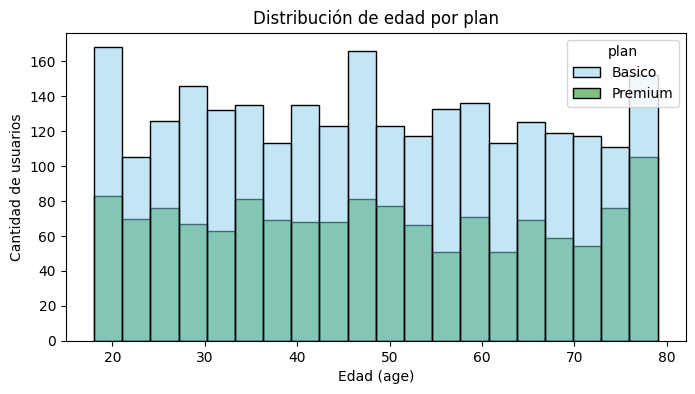

In [ ]:

# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 4))
sb.histplot(data=user_profile, x="age", hue="plan", palette=["skyblue", "green"], kde=False, bins=20)
plt.title("Distribución de edad por plan")
plt.xlabel("Edad (age)")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights:

- Distribución relativamente uniforme/equilibrada a lo largo de las edades, sin un sesgo marcado.
- No hay una diferencia pronunciada entre Básico y Premium; ambos planes reparten usuarios de forma parecida en los distintos rangos de edad.

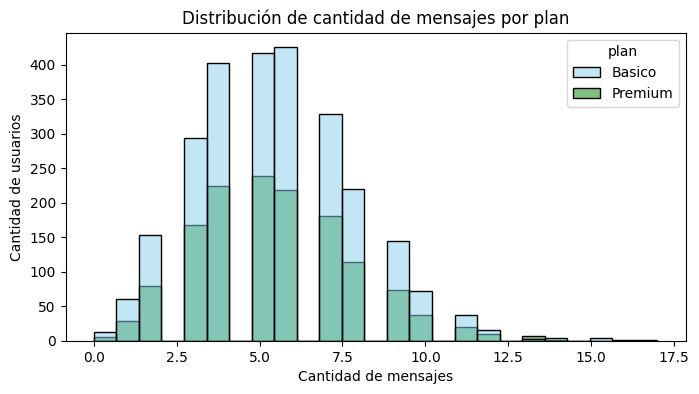

In [ ]:
# Histograma para visualizar cant_mensajes
plt.figure(figsize=(8, 4))
sb.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=["skyblue", "green"], kde=False, bins=25)
plt.title("Distribución de cantidad de mensajes por plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights:
- Forma: Distribución concentrada entre 3 y 8 mensajes (pico cerca de 5–6), con una cola ligera hacia la derecha hasta alrededor de 17 mensajes.
- Por plan: Ambos planes siguen una forma similar, aunque Básico aporta la mayor cantidad de usuarios en casi todos los rangos y en los valores altos (por encima de 13) sólo aparecen unos pocos casos aislados.   

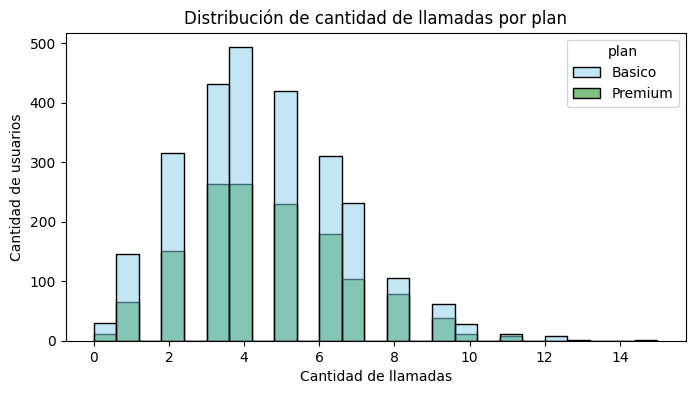

In [ ]:

# Histograma para visualizar cant_llamadas
plt.figure(figsize=(8, 4))
sb.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=["skyblue", "green"], kde=False, bins=25)
plt.title("Distribución de cantidad de llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()




💡Insights:
 - Forma: Distribución concentrada entre 2 y 7 llamadas (pico cerca de 3–4 llamadas, rondando casi los 500 usuarios), con un ligero sesgo hacia la derecha hasta alrededor de 14–15 llamadas.  
 - Por plan: Ambos planes presentan una forma de campana ligeramente asimétrica similar, pero Básico concentra mayor cantidad de usuarios en casi todos los niveles y los pocos registros por encima de 12 llamadas corresponden casi exclusivamente a usuarios Básico

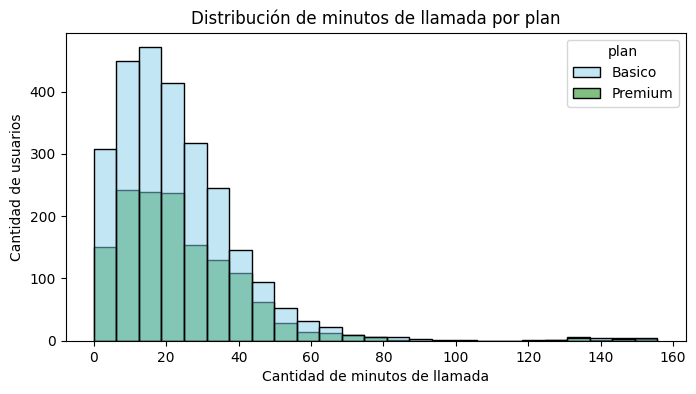

In [ ]:
# Histograma para visualizar cant_minutos_llamada
plt.figure(figsize=(8, 4))
sb.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=["skyblue", "green"], kde=False, bins=25)
plt.title("Distribución de minutos de llamada por plan")
plt.xlabel("Cantidad de minutos de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights:
- Forma: Distribución sesgada a la derecha, con la mayoría concentrada entre 0 y 40 minutos (pico cerca de 15 minutos, rondando los 470 usuarios) y una cola larga hacia valores altos que llega hasta cerca de 150–160 minutos.
- Por plan: Ambos planes siguen este mismo patrón asimétrico, aunque Básico acumula mayor cantidad de usuarios en los rangos bajos y medios (hasta 60 minutos), mientras que en el extremo superior (130–155 minutos) aparecen unos pocos usuarios principalmente de Premium y Básico.   

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

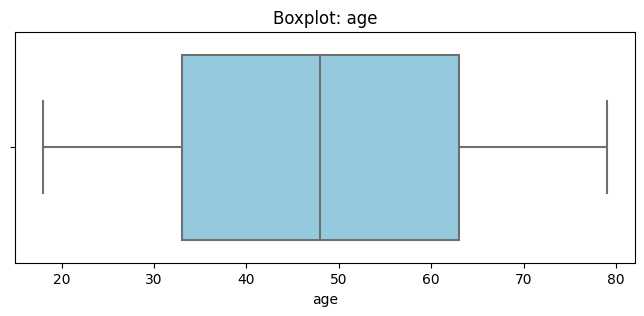

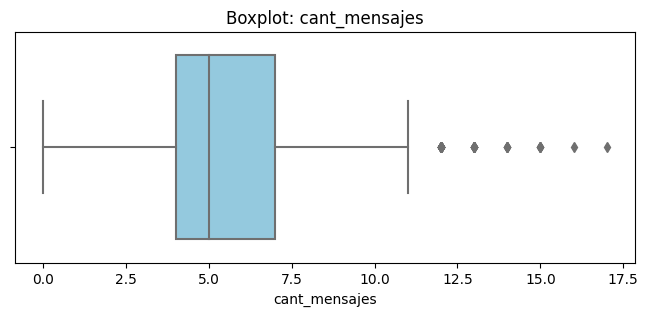

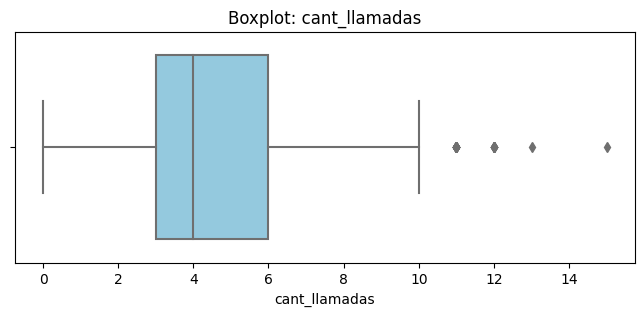

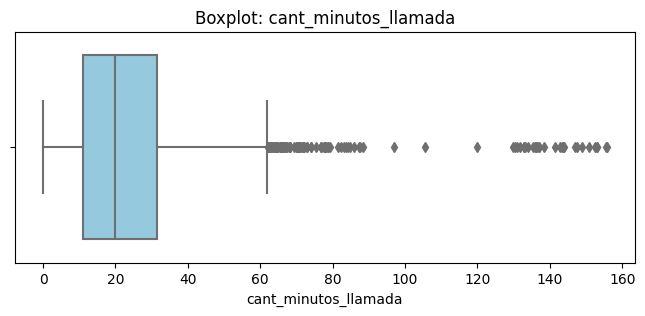

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sb.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- Age: No presenta outliers; la distribución es simétrica entre 18 y 79 años, con mediana cercana a 48 y rango intercuartílico entre 33 y 63.
- cant_mensajes: Sí presenta outliers únicamente en el extremo superior (valores entre 12 y 17 mensajes), con la mayoría concentrada entre 4 y 7 mensajes y mediana cerca de 5.
- cant_llamadas: Sí presenta outliers únicamente en el extremo superior (valores puntuales entre 11 y 15 llamadas), con mediana en 4 y rango intercuartílico entre 3 y 6 llamadas.
- cant_minutos_llamada: Sí presenta outliers únicamente en el extremo superior (valores por encima de 62 minutos, llegando hasta cerca de 157 minutos), con mediana alrededor de 20 minutos y mayor concentración entre 10 y 31 minutos

In [ ]:
# Calcular límites con el método IQR (solo límite superior por sesgo a la derecha)
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr

    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f} -> Límite superior={limite_superior:.2f} | Outliers={n_outliers}")

cant_mensajes: Q1=4.00, Q3=7.00, IQR=3.00 -> Límite superior=11.50 | Outliers=46
cant_llamadas: Q1=3.00, Q3=6.00, IQR=3.00 -> Límite superior=10.50 | Outliers=30
cant_minutos_llamada: Q1=11.11, Q3=31.41, IQR=20.30 -> Límite superior=61.87 | Outliers=109


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights:

- cant_mensajes: Mantener, porque los valores altos (hasta 17 mensajes) son plausibles para usuarios más activos y eliminarlos ocultaría parte del consumo real.
- cant_llamadas: Mantener, ya que los valores por encima del límite (hasta 15 llamadas) reflejan frecuencias elevadas pero realistas en el uso del servicio, no errores de captura.
- cant_minutos_llamada: Mantener, dado que los totales altos (hasta cerca de 157 minutos) representan clientes con mayor duración acumulada de llamadas y conviene conservarlos para no subestimar el uso intensivo (apoyándose en mediana e IQR al comparar planes).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
condiciones = [
    (user_profile["cant_llamadas"] < 5) & (user_profile["cant_mensajes"] < 5),
    (user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10),
]

categorias = ["Bajo uso", "Uso medio"]

user_profile["grupo_uso"] = np.select(condiciones, categorias, default="Alto uso")

# Revisar distribución resultante
print(user_profile["grupo_uso"].value_counts())

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad


🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos


In [ ]:
# Crear columna grupo_edad
import numpy as np

# Crear columna grupo_edad
condiciones_edad = [
    user_profile["age"] < 30,
    user_profile["age"] < 60,
]

grupos_edad = ["Joven", "Adulto"]

user_profile["grupo_edad"] = np.select(condiciones_edad, grupos_edad, default="Adulto Mayor")

# Verificar distribución por grupo de edad
print(user_profile["grupo_edad"].value_counts())

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

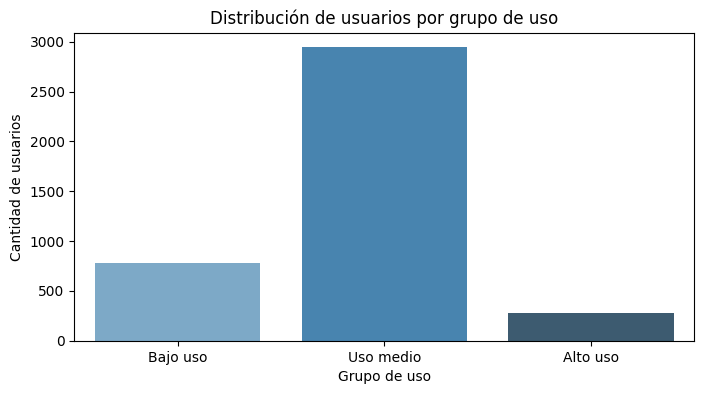

In [ ]:
# Visualización de los segmentos por uso
plt.figure(figsize=(8, 4))
sb.countplot(
    data=user_profile,
    x="grupo_uso",
    order=["Bajo uso", "Uso medio", "Alto uso"],
    palette="Blues_d"
)
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()

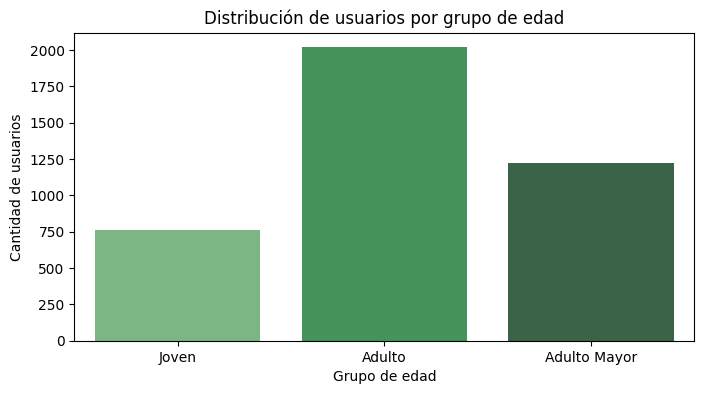

In [ ]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 4))
sb.countplot(
    data=user_profile,
    x="grupo_edad",
    order=["Joven", "Adulto", "Adulto Mayor"],
    palette="Greens_d"
)
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
* **`users['city']`**: 469 nulos (~11.73%–11.75%) y 96 valores `"?"` (2.4%), sumando 565 registros faltantes o desconocidos tras pasar `"?"` a `pd.NA`.
* **`users['churn_date']`**: 3,534 nulos (88.35%), coherente con clientes activos/sin baja (466 con baja).
* **`users['age']`**: valor centinela `-999` (rango válido: 18–79 años) que sesgaba la media (`33.74` antes vs. `48.14` tras imputar con la mediana de `48.0`); conteo exacto no especificado.
* **`users['reg_date']`**: 40 registros (1.0%) con año `2026` (fuera del límite hasta 2024), marcados como `pd.NaT`.
* **`usage['date']`**: 50 valores nulos/no parseables (0.125%, citado como 0.12%).
* **`usage['duration']` y `usage['length']`**: 22,076 (55.19%) y 17,896 (44.74%) nulos respectivamente; siguen un patrón **MAR** según `type` (`call` vs. `text`) y se conservaron como nulos.

🔍 **Segmentos por Edad**
* Base de 4,000 usuarios de **18 a 79 años** (media **48.14**, mediana **48.0**, DE **17.69**, Q1 = 33, Q3 = 63).
* Distribución equilibrada entre rangos y sin diferencias marcadas entre **Básico** y **Premium**.

📊 **Segmentos por Nivel de Uso**
* **Mensajes (`cant_mensajes`)**: media **5.52**, mediana **5.00** (Q1 = 4, Q3 = 7, rango 0–17), concentrados entre 3 y 8 con cola derecha leve.
* **Llamadas (`cant_llamadas`)**: media **4.48**, mediana **4.00** (Q1 = 3, Q3 = 6, rango 0–15), forma acampanada con leve sesgo positivo (concentración entre 2 y 7).
* **Minutos (`cant_minutos_llamada`)**: media **23.31**, mediana **19.78** (Q1 = 11.11, Q3 = 31.41, rango 0.0–155.69), sesgo positivo y mayor concentración entre 0 y 40 min (pico cerca de 15 min).
* **Por plan**: **Básico** reúne el **64.88%** (2,595) y **Premium** el **35.12%** (1,405); Básico lidera en volumen en casi todos los rangos hasta ~60 minutos.

➡️ El uso habitual es moderado y concentrado en rangos bajos-medios, con predominio volumétrico de **Básico** y poca influencia de la edad en la elección de plan.

💡 **Recomendaciones**
* **Segmentos más valiosos**: sin métricas de ingreso, margen, LTV ni *churn* en el notebook.
* ***Outliers* e impacto en negocio**:
  * Se hallaron **30 registros en `120.0`** en `duration` (p99 = `23.69`, siguiente valor `46.98`) y **30 en `1490.0`** en `length` (p99 = `97.0`, siguiente `125.0`), además de colas derechas en mensajes (máx. 17), llamadas (máx. 15) y minutos (máx. 155.69).
  * Sobre 12 llamadas predominan casi exclusivamente usuarios **Básico**; entre 130 y 155 minutos aparecen pocos casos, sobre todo de **Premium** y **Básico**.
  * Los valores fijos `120.0` y `1490.0` deben validarse como posibles topes técnicos, centinelas o errores antes de facturar o modelar, y los picos reales en **Básico** sugieren exposición a cargos extra o fricción por límites.
* **Mejora o creación de planes**:
  * Calibrar planes actuales (`Basico` vs. `Premium`) según el consumo real y confirmar reglas de red detrás de `120.0` y `1490.0`.
  * Diseñar opciones intermedias o escalonadas para usuarios con consumo alto o picos recurrentes (sobre todo en **Básico**), equilibrando ingresos por extras y retención, y mejorar la captura de `city` y `reg_date`.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: https://github.com/marianafm01/sprint7-final-project